# 10 — Phase 3 follow-ups: fold-to-fold variation, what is deployed, the outreach pilot, and a replayed day

This notebook documents the additions made for the final phase, each of which answers a point of the
Phase 2 evaluation. Nothing is refitted here: every table is read from `report/results/`, exactly as
`src/selection_tables.py`, `src/pilot_design.py` and `src/train_models.py` wrote it, and every number
shown is one the final report quotes (`report/stats_phase3.txt`).

| Phase 2 feedback | Where this notebook shows it |
|---|---|
| Report CV scores with their fold-to-fold variation for the Problem 2 candidates | §10.1 |
| State the deployed Problem 2 model clearly and consistently, and justify the choice | §10.2 |
| The selected hyperparameter values were not in Appendix C | §10.3 |
| The expected benefit assumes a contact prevents the low review: state it, propose a pilot | §10.4 |
| (Phase 3 brief) the app predicts on held-out historical records simulating new orders | §10.5 |

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config
from viz import use_report_style
use_report_style()

RESULTS = ROOT / "report" / "results"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("results:", RESULTS)

results: E:\2025 NUS\IT5006\IT5006 PROJECT\report\results


## 10.1 Fold-to-fold variation of every candidate

The training script scored every candidate on each of the five expanding-window folds and on the validation
period (`selection_*.csv`). `src/selection_tables.py` lays those out as `cv_folds.csv`, one row per candidate,
with the mean, the population standard deviation over the five folds (the same quantity scikit-learn reports as
`std_test_score`, and the `cv_std` column the results tables already carried), the range, and the test score.

In [2]:
folds = pd.read_csv(RESULTS / "cv_folds.csv")
FOLDS = [f"fold{i}" for i in range(1, 6)]
p2 = folds[folds["problem"] == "P2 low review"].sort_values("mean_rank_recent").reset_index(drop=True)
p2[["model"] + FOLDS + ["validation", "cv_mean", "cv_sd", "cv_range", "test", "mean_rank_recent", "deployed"]].round(4)

,model,fold1,fold2,fold3,fold4,fold5,validation,cv_mean,cv_sd,cv_range,test,mean_rank_recent,deployed
0,StackingClassifier (A+B),0.4135,0.5371,0.6173,0.6600,0.6141,0.4095,0.5684,0.0870,0.2465,0.4137,1.6667,True
1,HistGradientBoostingClassifier,0.4106,0.5394,0.6183,0.6602,0.6133,0.4068,0.5684,0.0879,0.2496,0.4148,2.0000,False
2,RandomForestClassifier,0.4045,0.5442,0.6225,0.6538,0.6158,0.4031,0.5681,0.0893,0.2493,0.4045,2.6667,False
3,"VotingClassifier (A+B, soft)",0.4127,0.5263,0.6111,0.6503,0.6036,0.4036,0.5608,0.0843,0.2376,0.4074,3.6667,False
4,DecisionTreeClassifier,0.3803,0.5097,0.5954,0.6399,0.5917,0.3885,0.5434,0.0918,0.2596,0.3958,5.0000,False
5,LogisticRegression (tuned L2),0.3065,0.4161,0.5344,0.5739,0.4972,0.3196,0.4656,0.0951,0.2674,0.2905,6.3333,False
6,LogisticRegression,0.3072,0.4156,0.5336,0.5739,0.4971,0.3195,0.4655,0.0948,0.2667,0.2905,6.6667,False


Read down a column, the windows differ far more than the models; read across a row, the three tree-based rungs
are inseparable. The quantity the feedback asks about — can cross-validation separate the best candidates? — is
the gap between the top two means expressed in fold-to-fold standard deviations:

In [3]:
top = p2.sort_values("cv_mean", ascending=False).reset_index(drop=True)
gap = top.loc[0, "cv_mean"] - top.loc[1, "cv_mean"]
sd = p2["cv_sd"].median()
window_means = p2[FOLDS].mean(axis=0)
within = p2[FOLDS].std(axis=0, ddof=0)
print(f"best two by CV mean: {top.loc[0, 'model']} vs {top.loc[1, 'model']}")
print(f"gap between them     : {gap:.5f} PR-AUC")
print(f"median fold-to-fold sd: {sd:.3f}  ->  gap = {gap / sd:.4f} standard deviations")
print(f"window means run from {window_means.min():.3f} (fold {window_means.idxmin()[-1]}) "
      f"to {window_means.max():.3f} (fold {window_means.idxmax()[-1]}); "
      f"median within-window spread of the candidates {within.median():.3f}")

best two by CV mean: StackingClassifier (A+B) vs HistGradientBoostingClassifier
gap between them     : 0.00004 PR-AUC
median fold-to-fold sd: 0.089  ->  gap = 0.0005 standard deviations
window means run from 0.376 (fold 1) to 0.630 (fold 4); median within-window spread of the candidates 0.045


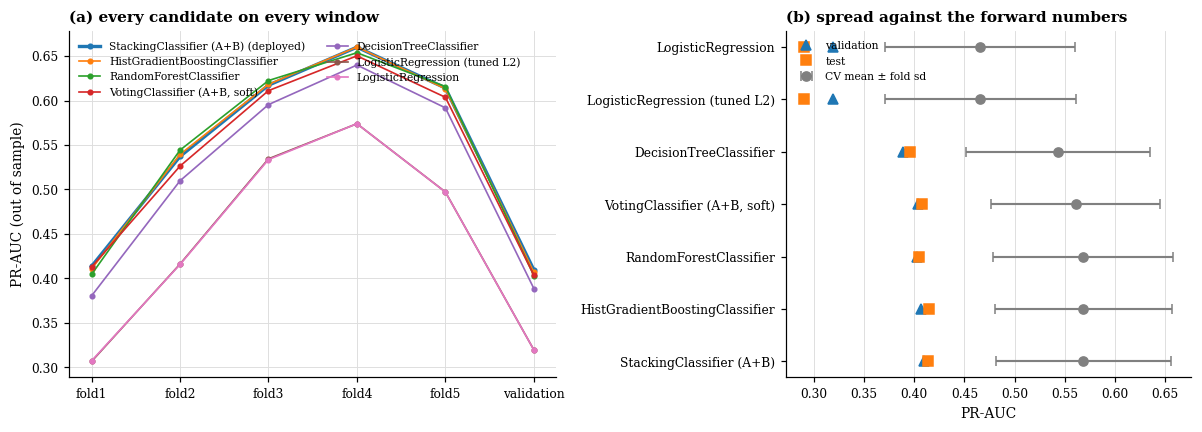

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.2, 1]})
x = np.arange(6)
for _, r in p2.iterrows():
    ax1.plot(x, r[FOLDS + ["validation"]].astype(float).to_numpy(), marker="o", ms=3,
             lw=2.2 if r["deployed"] else 1.1, label=r["model"] + (" (deployed)" if r["deployed"] else ""))
ax1.set_xticks(x); ax1.set_xticklabels(FOLDS + ["validation"])
ax1.set_ylabel("PR-AUC (out of sample)"); ax1.set_title("(a) every candidate on every window", loc="left")
ax1.legend(fontsize=7, loc="upper left", ncol=2)
y = np.arange(len(p2))
ax2.errorbar(p2["cv_mean"], y, xerr=p2["cv_sd"], fmt="o", color="grey", capsize=3, label="CV mean ± fold sd")
ax2.plot(p2["validation"], y, "^", label="validation")
ax2.plot(p2["test"], y, "s", label="test")
ax2.set_yticks(y); ax2.set_yticklabels(p2["model"], fontsize=8)
ax2.set_xlabel("PR-AUC"); ax2.set_title("(b) spread against the forward numbers", loc="left")
ax2.legend(fontsize=7, loc="upper left"); ax2.grid(axis="y", visible=False)
plt.tight_layout()

The same table exists for Problems 1A and 1B. For the regression the folds are stored as positive MAE:

In [5]:
p1a = folds[folds["problem"] == "P1A lead time"].sort_values("mean_rank_recent")
p1a[["model"] + FOLDS + ["validation", "cv_mean", "cv_sd", "test", "mean_rank_recent", "deployed"]].round(3)

,model,fold1,fold2,fold3,fold4,fold5,validation,cv_mean,cv_sd,test,mean_rank_recent,deployed
0,VotingRegressor (A+B),4.327,4.403,5.843,6.602,5.399,4.784,5.315,0.866,3.898,2.333,True
1,StackingRegressor (A+B),4.494,4.415,5.871,6.534,5.902,4.792,5.443,0.841,4.121,2.667,False
2,Ridge,3.950,4.485,5.865,6.608,5.097,5.164,5.201,0.950,4.309,3.667,False
3,HistGradientBoostingRegressor,4.651,4.465,5.878,6.612,5.870,4.802,5.495,0.813,4.141,4.000,False
4,LinearRegression,3.989,4.454,5.958,6.755,5.055,4.965,5.242,1.003,4.181,4.000,False
5,RandomForestRegressor,4.283,4.491,5.944,6.560,6.006,5.513,5.457,0.902,4.956,5.000,False
6,DecisionTreeRegressor,4.287,4.665,6.170,6.646,5.928,5.927,5.539,0.906,6.116,6.333,False


## 10.2 What is deployed, read from the artifacts

The Phase 2 report named the deployed Problem 2 model inconsistently in three places. The artifacts settle it,
and `tests/test_leakage.py` now asserts that `models/model_metadata.json`, the pickles, `hyperparameters.csv`,
the README and the final report's deployment section all name the same estimators.

In [6]:
import modeling as M
meta = json.loads((ROOT / "models" / "model_metadata.json").read_text("utf-8"))
rows = []
for tag, fname in [("p1a", "p1a_leadtime.joblib"), ("p1b", "p1b_margin_to_risk.joblib"), ("p2", "p2_lowreview.joblib")]:
    b = M.load_model(ROOT / "models" / fname)
    est = b["estimator"]
    members = ""
    if hasattr(est, "estimators"):
        members = " + ".join(f"{n}={type(m.steps[-1][1]).__name__}" for n, m in est.estimators)
    fe = getattr(est, "final_estimator_", None)
    rows.append({"problem": tag, "metadata label": meta[tag].get("label", meta[tag].get("route")),
                 "pickled label": b["label"], "class": type(est).__name__, "members": members,
                 "weights": getattr(est, "weights", None),
                 "meta-learner coef (linear, tree)": np.ravel(fe.coef_).round(3).tolist() if fe is not None else None,
                 "KB": round((ROOT / "models" / fname).stat().st_size / 1e3)})
pd.DataFrame(rows)

,problem,metadata label,pickled label,class,members,weights,"meta-learner coef (linear, tree)",KB
0,p1a,VotingRegressor (A+B),VotingRegressor (A+B),VotingRegressor,linear=LinearRegression + tree=HistGradientBoo...,"[1, 2]",None,381
1,p1b,Derived: regression margin vs promise,LogisticRegression on (predicted days - promis...,LogisticRegression,,None,None,1
2,p2,StackingClassifier (A+B),StackingClassifier (A+B),StackingClassifier,linear=LogisticRegression + tree=HistGradientB...,None,"[0.405, 5.572]",321


**Why the stack is served rather than the single boosted model.** On the test window the two are within
0.001 PR-AUC (0.414 vs 0.415), and the meta-learner weights the tree member 13.8× the linear one, so the stack
is very nearly the boosted model with a small linear correction. It is kept because the selection rule —
best mean rank over the three most recent out-of-sample windows — was fixed before any test score was seen,
and it chose the stack (mean rank 1.67 vs 2.00). Switching afterwards would be selecting on the test set.

In [7]:
sel = p2.set_index("model").loc[["StackingClassifier (A+B)", "HistGradientBoostingClassifier"]]
print(sel[FOLDS + ["validation", "cv_mean", "test", "mean_rank_recent"]].round(4).T)
print("\nwindows on which the stack is ahead:",
      int(sum(sel.iloc[0][w] > sel.iloc[1][w] for w in FOLDS + ["validation"])), "of 6")

model             StackingClassifier (A+B)  HistGradientBoostingClassifier
fold1                               0.4135                          0.4106
fold2                               0.5371                          0.5394
fold3                               0.6173                          0.6183
fold4                               0.6600                          0.6602
fold5                               0.6141                          0.6133
validation                          0.4095                          0.4068
cv_mean                             0.5684                          0.5684
test                                0.4137                          0.4148
mean_rank_recent                    1.6667                          2.0000

windows on which the stack is ahead: 3 of 6


## 10.3 Selected hyperparameters

`hyperparameters.csv` lists the value RandomizedSearchCV selected for every searched model and, for the two
deployed ensembles, the values their members carry (read from the pickles). The test suite checks that each
deployed member matches its tuned candidate.

In [8]:
hp = pd.read_csv(RESULTS / "hyperparameters.csv")
hp[hp["role"] == "candidate"].pivot_table(index=["problem", "model"], columns="parameter", values="value",
                                         aggfunc="first").fillna("")

parameter                                            C  alpha l2_regularization learning_rate max_depth max_features max_iter max_leaf_nodes min_samples_leaf n_estimators
problem       model                                                                                                                                                       
P1A lead time DecisionTreeRegressor                                                                  17       0.8972                                      158             
              HistGradientBoostingRegressor                               9.142        0.1065                             433             36              117             
              RandomForestRegressor                                                                  14       0.1645                                      107          150
              Ridge                                     659.9                                                                                                             
P1B late flag DecisionTreeClassifier                                                                  9       0.8779                                      290             
              HistGradientBoostingClassifier                              8.244       0.07079                             426             21               30             
              LogisticRegression (tuned L2)   0.004983                                                                                                                    
              RandomForestClassifier                                                                 13       0.2997                                      132          150
P2 low review DecisionTreeClassifier                                                                 14       0.9631                                      211             
              HistGradientBoostingClassifier                            0.01789       0.02073                             208             28               18             
              LogisticRegression (tuned L2)      8.431                                                                                                                    
              RandomForestClassifier                                                                 12       0.3491                                       44          150

In [9]:
hp[hp["role"] != "candidate"][["problem", "model", "role", "estimator", "parameter", "value"]]

,problem,model,role,estimator,parameter,value
40,P1A lead time,VotingRegressor (A+B),deployed ensemble,VotingRegressor,weights (linear : tree),1:2
41,P1A lead time,VotingRegressor (A+B),deployed member: linear,LinearRegression,(no free parameters),NaN
42,P1A lead time,VotingRegressor (A+B),deployed member: tree,HistGradientBoostingRegressor,max_iter,433
43,P1A lead time,VotingRegressor (A+B),deployed member: tree,HistGradientBoostingRegressor,learning_rate,0.1065
44,P1A lead time,VotingRegressor (A+B),deployed member: tree,HistGradientBoostingRegressor,max_leaf_nodes,36
45,P1A lead time,VotingRegressor (A+B),deployed member: tree,HistGradientBoostingRegressor,min_samples_leaf,117
46,P1A lead time,VotingRegressor (A+B),deployed member: tree,HistGradientBoostingRegressor,l2_regularization,9.142
47,P2 low review,StackingClassifier (A+B),deployed ensemble,StackingClassifier,meta-learner,LogisticRegression(C=1.0)
48,P2 low review,StackingClassifier (A+B),deployed ensemble,StackingClassifier,"meta-learner coefficients (linear, tree)","0.405, 5.572"
49,P2 low review,StackingClassifier (A+B),deployed member: linear,LogisticRegression,C,8.431


## 10.4 The outreach pilot

Section 9.2 of the report values a contact at the review it prevents. Nobody in this data was ever contacted,
so that counterfactual is unobserved. `src/pilot_design.py` sizes the randomised experiment that would measure
it: inside each day's top-K list, contact half at random and leave half; compare the 1–2 star rate of the two
arms. The control arm's rate is already known — the model's precision at that daily K on the test window.

In [10]:
be = pd.read_csv(RESULTS / "pilot_breakeven.csv")
be.round(3)

,k_per_day,flagged_pct,control_rate,breakeven_absolute_reduction,breakeven_relative_reduction,n_per_arm_80_at_breakeven,weeks_80_at_breakeven
0,5,2.404,0.631,0.125,0.198,246.0,15.0
1,10,4.776,0.572,0.125,0.219,250.0,8.0
2,20,9.475,0.440,0.125,0.284,235.0,4.0
3,40,18.810,0.297,0.125,0.421,180.0,2.0


In [11]:
design = pd.read_csv(RESULTS / "pilot_design.csv")
design[design["k_per_day"].isin([10, 20])][["k_per_day", "control_rate", "relative_reduction", "treated_rate",
    "n_per_arm_80", "weeks_80", "n_per_arm_90", "weeks_90", "net_benefit_per_contact", "above_break_even"]].round(3)

,k_per_day,control_rate,relative_reduction,treated_rate,n_per_arm_80,weeks_80,n_per_arm_90,weeks_90,net_benefit_per_contact,above_break_even
7,10,0.572,0.10,0.514,1191.0,35.0,1594.0,46.0,-2.713,False
8,10,0.572,0.15,0.486,531.0,16.0,711.0,21.0,-1.570,False
9,10,0.572,0.20,0.457,299.0,9.0,400.0,12.0,-0.427,False
10,10,0.572,0.25,0.429,191.0,6.0,256.0,8.0,0.717,True
11,10,0.572,0.30,0.400,133.0,4.0,177.0,6.0,1.860,True
12,10,0.572,0.40,0.343,74.0,3.0,98.0,3.0,4.147,True
13,10,0.572,0.50,0.286,46.0,2.0,61.0,2.0,6.433,True
14,20,0.440,0.10,0.396,1971.0,29.0,2638.0,38.0,-3.240,False
15,20,0.440,0.15,0.374,869.0,13.0,1162.0,17.0,-2.360,False
16,20,0.440,0.20,0.352,484.0,7.0,647.0,10.0,-1.479,False


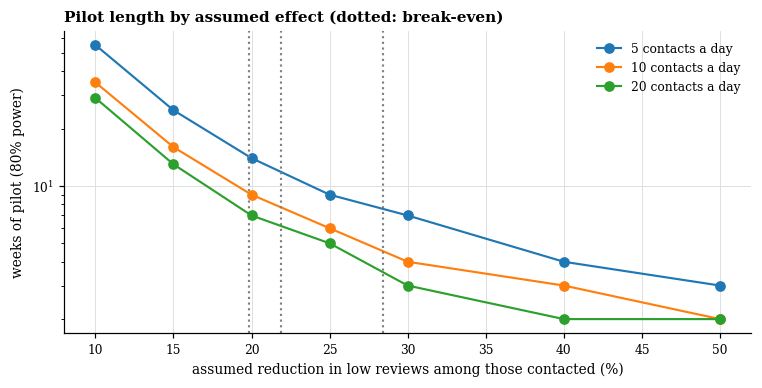

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, g in design[design["k_per_day"].isin([5, 10, 20])].groupby("k_per_day"):
    ax.plot(100 * g["relative_reduction"], g["weeks_80"], "o-", label=f"{k} contacts a day")
    ax.axvline(100 * float(be.set_index("k_per_day").loc[k, "breakeven_relative_reduction"]), ls=":", color="grey")
ax.set_yscale("log"); ax.set_xlabel("assumed reduction in low reviews among those contacted (%)")
ax.set_ylabel("weeks of pilot (80% power)"); ax.set_title("Pilot length by assumed effect (dotted: break-even)", loc="left")
ax.legend(); plt.tight_layout()

At ten contacts a day a contact must avert roughly one low review in five (21.9%) to pay for itself under the
R$5 : R$40 assumption; a pilot sized for a one-in-four effect runs about six weeks at 80% power.

## 10.5 A replayed day from the held-out window

The deployed application replays any purchase day of the test window (1 July – 31 August 2018) — orders never
used to fit, tune or threshold anything — ranked by the deployed review model's score, and reveals the real
outcomes. This is the same computation, for 16 July 2018 at a capacity of ten.

In [13]:
pred = pd.read_csv(RESULTS / "predictions_p2_test.csv", parse_dates=["order_purchase_timestamp"])
pred["day"] = pred["order_purchase_timestamp"].dt.date
day = pd.Timestamp("2018-07-16").date()
g = pred[pred["day"] == day].sort_values("p_low_review", ascending=False).reset_index(drop=True)
K = 10
top = g.head(K)
print(f"{day}: {len(g)} orders placed; {int(g['actual_low_review'].sum())} left a 1-2 star review")
print(f"top-{K} by review risk: {int(top['actual_low_review'].sum())} of {K} did  ->  precision {top['actual_low_review'].mean():.2f}, "
      f"recall {top['actual_low_review'].sum() / g['actual_low_review'].sum():.2f}")
top[["order_id", "customer_state", "lead_category", "estimated_days", "p_low_review", "actual_low_review"]].round(3)

2018-07-16: 244 orders placed; 31 left a 1-2 star review
top-10 by review risk: 8 of 10 did  ->  precision 0.80, recall 0.26


,order_id,customer_state,lead_category,estimated_days,p_low_review,actual_low_review
0,e1320973675a5fc37fab54cb22c582ab,RJ,health_beauty,21.294,0.847,1
1,8eabb0219281482f84013cbc8a4e5364,SP,stationery,9.162,0.802,0
2,d35703faec55cda0ceeb4f50a4d584ae,SP,auto,13.077,0.763,0
3,c0902caa9df6e499f3aa6d5acb55f6c5,PE,home_confort,20.400,0.760,1
4,6ffc78c9003aa616f58b4de610bcce29,SP,health_beauty,17.419,0.758,1
5,f50b9192b9705d537f9593b595da132f,SP,health_beauty,9.385,0.756,1
6,b67ec1ba150cc097d3ab518272e6cf3f,SP,health_beauty,17.305,0.754,1
7,82f4c933483d577ca9f00f49b1203155,SP,health_beauty,14.407,0.750,1
8,5d052bba15113c0ee4700d9916844605,MG,sports_leisure,14.572,0.736,1
9,1469262ec8414d0e3f821bda79cf14cc,MG,auto,21.523,0.734,1


62 days; mean precision of the daily top-10: 0.571; pooled (capacity_p2_daily.csv): 0.572


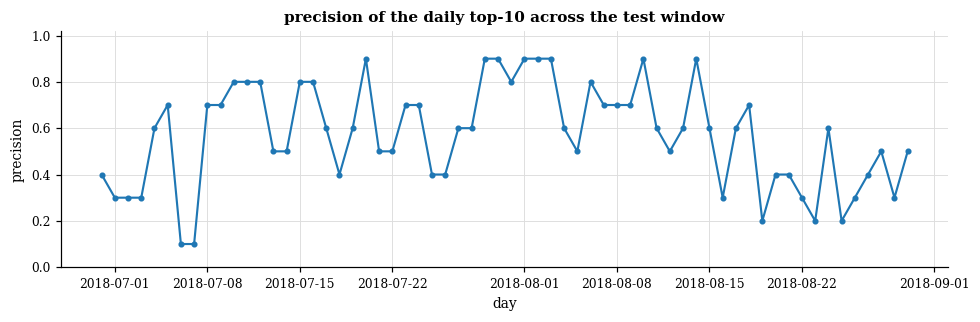

In [14]:
# the same capacity on every day of the window - what the application's right-hand chart shows
ranked = pred.sort_values(["day", "p_low_review"], ascending=[True, False], kind="stable")
ranked["pos"] = ranked.groupby("day").cumcount()
daily = ranked[ranked["pos"] < K].groupby("day")["actual_low_review"].agg(["sum", "size"])
daily["precision"] = daily["sum"] / daily["size"]
print(f"{len(daily)} days; mean precision of the daily top-{K}: {daily['precision'].mean():.3f}; "
      f"pooled (capacity_p2_daily.csv): {pd.read_csv(RESULTS / 'capacity_p2_daily.csv').set_index('k_per_period').loc[K, 'precision']:.3f}")
daily["precision"].plot(figsize=(9, 3), marker="o", ms=3, title=f"precision of the daily top-{K} across the test window");
plt.ylim(0, 1.02); plt.ylabel("precision"); plt.tight_layout()

### Takeaways

1. The fold-to-fold spread (±0.09 PR-AUC) is a property of the windows, not the models, and it dwarfs the gaps
   between the best candidates — the empirical case for the rank-based selection rule.
2. What is deployed is now a fact checked by a test: VotingRegressor for lead time, the derived route for the late
   flag, StackingClassifier for review risk, with every member's hyperparameters printed.
3. The business case rests on one untested assumption, and the pilot that would test it is short at the effect
   sizes that matter: six weeks at ten contacts a day.
4. Replaying a held-out day shows the ranked list doing what the pooled metrics say it does.